# Step 7e: The ratio idea (predict a multiplier, not £)

Same rules as before: winner by **R² in £** (MAE breaks ties), **5-fold CV on train only**, **250 Optuna trials**, features **R, F, M**, **test not touched**.

## The problem we are fixing
In 7b, 7c and 7d every tree model failed in the same place: the few giant customers. Trees answer with averages of what they were trained on, so they cannot output £100k+ (largest prediction about £50k vs £110k real).

## The idea
```
scale      = max(Monetary, £50)            the customer's own past spend
multiplier = future spend / scale           what the trees learn
prediction = predicted multiplier × scale
```
The **scale comes from the customer**, so a customer with £300k past spend automatically gets a big prediction even if the trees only learned "multiplier ≈ 0.3". And a *constant* multiplier of 0.37 is exactly the past-spend baseline, so this model can only improve on the baseline by *correcting* it with Recency and Frequency.

Details:
- **Floor £50:** a tiny past spend with a real future spend would give a huge multiplier, and Monetary can be ≤ 0 (14 customers). 73 customers are below the floor.
- **Weights:** each customer is weighted by `scale ** weight_power` (Optuna picks `weight_power` between 0 and 2). Power 2 makes the fit minimise squared error in £ exactly; power 0 treats every customer's multiplier the same.
- **Two variants** (same boosted trees, different loss): squared error on the multiplier, and Tweedie on the multiplier.

Tuned: the usual five XGBoost settings + `weight_power` (+ `tweedie_variance_power` for Tweedie). Code: `src/step7e_ratio.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2, revenue_capture
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, PastSpendBaseline, cv_predictions, score_table
from step7a_ridge_log import LogRidge
from step7b_xgboost import XGBModel, oof_with_seed
from step7c_tweedie import XGBTweedie
from step7d_hurdle import HurdleModel, BEST_7D_LOG
from step7e_ratio import RatioXGB, suggest_ratio, N_TRIALS, FLOOR, ALPHA_7A_SMEAR, BEST_7B, BEST_7C
from tuning import tune

pd.set_option("display.width", 220)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
X, y = build_rfm(train), train.target
ya = y.to_numpy()
scale = X["Monetary"].clip(lower=FLOOR).to_numpy()

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. How much does the real multiplier vary?

The past-spend rule uses ONE multiplier (about 0.37) for everybody. Among customers who actually bought, the real multiplier (future spend ÷ past spend) is:

real multiplier among buyers, quantiles 5/25/50/75/95%: [0.117 0.28  0.494 0.881 2.422]
share of customers who did not buy at all (multiplier 0): 52%


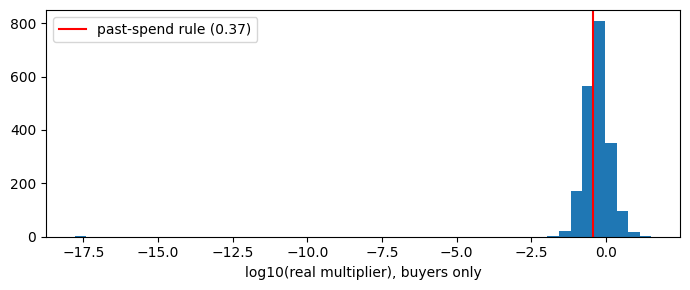

In [2]:
buys = ya > 0
mult = ya[buys] / scale[buys]
print("real multiplier among buyers, quantiles 5/25/50/75/95%:", np.quantile(mult, [.05, .25, .5, .75, .95]).round(3))
print("share of customers who did not buy at all (multiplier 0):", f"{(~buys).mean():.0%}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(mult), bins=50); ax.axvline(np.log10(0.37), color="red", label="past-spend rule (0.37)")
ax.set_xlabel("log10(real multiplier), buyers only"); ax.legend(); plt.tight_layout()

The real multiplier is all over the place (5th to 95th percentile: about 0.12 to 2.4). One constant cannot be right for everyone. The question is how much of that spread R, F, M can explain.

## 2. Tune both variants (250 trials each)

In [3]:
best, studies = {}, {}
for obj, label in (("squared", "Ratio XGBoost, squared error (7e)"), ("tweedie", "Ratio XGBoost, Tweedie (7e)")):
    tw = obj == "tweedie"
    st = tune(lambda obj=obj, **p: RatioXGB(objective=obj, **p), lambda trial, tw=tw: suggest_ratio(trial, tw), X, y, n_trials=N_TRIALS)
    best[label], studies[label] = st.best_params, st
    print(f"{label}: tuning score {st.best_value:.3f}")
    print("  ", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items()})

Ratio XGBoost, squared error (7e): tuning score 0.758
   {'n_estimators': 50, 'max_depth': 5, 'learning_rate': 0.0107, 'subsample': 0.3408, 'colsample_bytree': 0.9598, 'weight_power': 0.5568}


Ratio XGBoost, Tweedie (7e): tuning score 0.760
   {'n_estimators': 188, 'max_depth': 2, 'learning_rate': 0.0119, 'subsample': 0.7711, 'colsample_bytree': 0.6706, 'weight_power': 0.8569, 'tweedie_variance_power': 1.5008}


Look at the learning rates (about 0.011 to 0.012, right at the bottom of the range 0.01 to 0.3) and, for the squared-error variant, only 50 trees (the minimum). Optuna wants a model that **barely moves away from the starting guess**, the constant multiplier. That already hints that R, F, M add only a small correction.

## 3. Compare (train CV)

In [4]:
preds = {n: cv_predictions(c, X, y) for n, c in BASELINES.items()}
preds["LogRidge + smearing (7a)"] = cv_predictions(lambda: LogRidge(ALPHA_7A_SMEAR, True), X, y)
preds["XGBoost raw GBP (7b)"] = cv_predictions(lambda: XGBModel(**BEST_7B), X, y)
preds["XGBoost Tweedie (7c)"] = cv_predictions(lambda: XGBTweedie(**BEST_7C), X, y)
preds["Hurdle log+smear (7d)"] = cv_predictions(lambda: HurdleModel(log_stage2=True, **BEST_7D_LOG), X, y)
for obj, label in (("squared", "Ratio XGBoost, squared error (7e)"), ("tweedie", "Ratio XGBoost, Tweedie (7e)")):
    preds[label] = cv_predictions(lambda obj=obj, b=best[label]: RatioXGB(objective=obj, **b), X, y)

t = score_table(ya, preds)
t["total pred / total actual"] = [preds[k].sum() / ya.sum() for k in t.index]
display(t.round(3))
print("Same, without the 10 biggest customers:")
display(score_table(ya, preds, without_top=10).round(3))

print("Honest estimate: same settings on 10 other fold splits")
for obj, label in (("squared", "Ratio XGBoost, squared error (7e)"), ("tweedie", "Ratio XGBoost, Tweedie (7e)")):
    rs = [r2(ya, oof_with_seed(lambda obj=obj, b=best[label]: RatioXGB(objective=obj, **b), X, y, s)) for s in range(10)]
    print(f"  {label}: tuning score {studies[label].best_value:.3f} | other splits mean {np.mean(rs):.3f}, sd {np.std(rs):.3f}, range {min(rs):.3f} to {max(rs):.3f}")

,R2,MAE,Capture@20%,total pred / total actual
mean,-0.000,944.129,0.170,1.000
past_spend,0.746,523.153,0.739,1.001
LogRidge + smearing (7a),0.549,575.161,0.722,0.992
XGBoost raw GBP (7b),0.503,600.542,0.711,1.001
XGBoost Tweedie (7c),0.507,534.595,0.742,0.922
Hurdle log+smear (7d),0.561,535.792,0.746,0.968
"Ratio XGBoost, squared error (7e)",0.758,517.739,0.742,1.014
"Ratio XGBoost, Tweedie (7e)",0.760,507.546,0.741,0.987


Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686
LogRidge + smearing (7a),0.500,498.504,0.666
XGBoost raw GBP (7b),0.322,532.080,0.650
XGBoost Tweedie (7c),0.539,464.484,0.691
Hurdle log+smear (7d),0.491,469.402,0.693
"Ratio XGBoost, squared error (7e)",0.557,468.134,0.689
"Ratio XGBoost, Tweedie (7e)",0.569,458.772,0.687


Honest estimate: same settings on 10 other fold splits


  Ratio XGBoost, squared error (7e): tuning score 0.758 | other splits mean 0.731, sd 0.018, range 0.689 to 0.751


  Ratio XGBoost, Tweedie (7e): tuning score 0.760 | other splits mean 0.736, sd 0.023, range 0.674 to 0.759


**The giants problem is fixed.** R² jumps from about 0.5 (7b, 7c) and 0.56 (7d) to about **0.76**. The honest estimates (about 0.73 to 0.74) are in line with past spend (0.744).

## 4. The giants

In [5]:
top = np.argsort(-ya)[:10]
for k in ("past_spend", "XGBoost raw GBP (7b)", "XGBoost Tweedie (7c)", "Hurdle log+smear (7d)", "Ratio XGBoost, squared error (7e)", "Ratio XGBoost, Tweedie (7e)"):
    e = (ya - preds[k]) ** 2
    print(f"{k:36s} largest prediction {preds[k].max():>9,.0f} (actual max {ya.max():,.0f}) | share of squared error from the 10 biggest customers {e[top].sum() / e.sum():.0%}")

past_spend                           largest prediction   120,142 (actual max 110,668) | share of squared error from the 10 biggest customers 55%
XGBoost raw GBP (7b)                 largest prediction    54,109 (actual max 110,668) | share of squared error from the 10 biggest customers 66%
XGBoost Tweedie (7c)                 largest prediction    39,427 (actual max 110,668) | share of squared error from the 10 biggest customers 77%
Hurdle log+smear (7d)                largest prediction    50,632 (actual max 110,668) | share of squared error from the 10 biggest customers 71%
Ratio XGBoost, squared error (7e)    largest prediction   116,875 (actual max 110,668) | share of squared error from the 10 biggest customers 54%
Ratio XGBoost, Tweedie (7e)          largest prediction   101,445 (actual max 110,668) | share of squared error from the 10 biggest customers 55%


The largest predictions are now £101k to 117k (real maximum £110k), and the share of squared error from the 10 biggest customers falls from 66 to 77% down to 54 to 55%, which is the same as past spend. The trees no longer have to output big numbers; the scale does it.

## 5. What did the model actually learn?

The implied multiplier is `prediction ÷ scale`. The past-spend rule gives about 0.37 to everyone.

In [6]:
q = [.05, .25, .5, .75, .95]
rows = {n: np.quantile(preds[n] / scale, q) for n in ("past_spend", "Ratio XGBoost, squared error (7e)", "Ratio XGBoost, Tweedie (7e)")}
rows["REAL (buyers only)"] = np.quantile(mult, q)
display(pd.DataFrame(rows, index=["5%", "25%", "50%", "75%", "95%"]).T.round(3))

m = preds["Ratio XGBoost, Tweedie (7e)"] / scale
d = pd.DataFrame({"mult": m, "Recency": X.Recency, "Frequency": X.Frequency})
print("mean implied multiplier by Recency quartile (Tweedie):")
display(d.groupby(pd.qcut(d.Recency, 4, labels=["R1 recent", "R2", "R3", "R4 oldest"]), observed=True).mult.mean().round(3).to_frame("multiplier").T)
print("by Frequency bucket:")
display(d.groupby(pd.cut(d.Frequency, [0, 1, 2, 5, 10, 1e9], labels=["1", "2", "3-5", "6-10", "11+"]), observed=True).mult.mean().round(3).to_frame("multiplier").T)
imp = pd.Series(RatioXGB("tweedie", **best["Ratio XGBoost, Tweedie (7e)"]).fit(X, y).model_.feature_importances_, index=X.columns)
print("feature importance (Tweedie ratio model):", imp.round(3).to_dict())

,5%,25%,50%,75%,95%
past_spend,0.363,0.366,0.366,0.377,0.379
"Ratio XGBoost, squared error (7e)",0.326,0.351,0.369,0.391,0.461
"Ratio XGBoost, Tweedie (7e)",0.264,0.329,0.370,0.394,0.448
REAL (buyers only),0.117,0.280,0.494,0.881,2.422


mean implied multiplier by Recency quartile (Tweedie):


Recency,R1 recent,R2,R3,R4 oldest
multiplier,0.41,0.393,0.345,0.308


by Frequency bucket:


Frequency,1,2,3-5,6-10,11+
multiplier,0.369,0.359,0.356,0.367,0.382


feature importance (Tweedie ratio model): {'Recency': 0.3869999945163727, 'Frequency': 0.2590000033378601, 'Monetary': 0.3540000021457672}


The picture is clear:
- The model's multipliers span only **0.27 to 0.45** (5th to 95th percentile), around the same 0.37 as the baseline. The real ones span **0.12 to 2.4**. R, F, M cannot tell us which customers will be on the high or low end.
- What it did learn is a **recency adjustment**: recent customers get about 0.41, the oldest about 0.31. Frequency barely changes the multiplier (0.36 to 0.38). (Frequency and Monetary overlap, and Monetary is already the scale.)

So the ratio model = **past spend, nudged up for recent buyers and down for lapsed ones**.

## 6. Is the improvement over past spend real?

Paired bootstrap over customers (1,000 resamples): the difference between the Tweedie ratio model and past spend. (The tuning was done on the same data, so these intervals are slightly optimistic.)

In [7]:
ps, tw = preds["past_spend"], preds["Ratio XGBoost, Tweedie (7e)"]
rng = np.random.default_rng(0); n = len(ya)
ae_ps, ae_tw = np.abs(ya - ps), np.abs(ya - tw)
dm, dr, dc = [], [], []
for _ in range(1000):
    i = rng.integers(0, n, n)
    dm.append(ae_ps[i].mean() - ae_tw[i].mean())
    dr.append(r2(ya[i], tw[i]) - r2(ya[i], ps[i]))
    dc.append(revenue_capture(ya[i], tw[i]) - revenue_capture(ya[i], ps[i]))
pd.DataFrame({"mean": [np.mean(v) for v in (dm, dr, dc)],
              "95% low": [np.percentile(v, 2.5) for v in (dm, dr, dc)],
              "95% high": [np.percentile(v, 97.5) for v in (dm, dr, dc)]},
             index=["MAE gain in £ (past_spend minus ratio)", "R2 difference (ratio minus past_spend)", "Capture@20% difference"]).round(3)

,mean,95% low,95% high
MAE gain in £ (past_spend minus ratio),15.348,5.720,27.711
R2 difference (ratio minus past_spend),0.013,-0.013,0.044
Capture@20% difference,0.002,-0.003,0.008


- **MAE: a small but real gain** of about £15 per customer (about 3%), interval £6 to £28 (it excludes 0).
- **R²: no clear gain.** +0.013, interval -0.013 to +0.044 (includes 0).
- **Ranking (Capture@20%): a tie.** +0.002, interval -0.003 to +0.008.

## What we learned

| Train CV | R² (tuning) | R² (honest) | MAE (£) | Capture@20% | total pred / total actual | R² without top 10 |
|---|---|---|---|---|---|---|
| past_spend | 0.75 | 0.74 | 523 | 0.739 | 1.00 | 0.55 |
| Hurdle log+smear (7d), best tree-only | 0.56 | 0.52 | 536 | 0.746 | 0.97 | 0.49 |
| Ratio XGBoost, squared error (7e) | **0.758** | 0.731 ± 0.018 | 518 | 0.742 | 1.01 | 0.56 |
| **Ratio XGBoost, Tweedie (7e)** | **0.760** | 0.736 ± 0.023 | **508** | 0.741 | 0.99 | **0.57** |

- **The ratio idea fixed the giants problem completely:** R² from about 0.5 to about 0.76, largest prediction from £50k to £101k to 117k, calibration about 1.0.
- **But it only matches past spend, it does not clearly beat it.** The honest R² (0.73 to 0.74) is level with past spend (0.744). The one real gain is MAE (-£15, about 3%), plus a slightly better R² without the 10 biggest customers (0.57 vs 0.55).
- **Why so little?** The model starts from the past-spend rule and the only correction R, F, M can offer is a mild recency adjustment (multiplier 0.31 for lapsed customers up to 0.41 for recent ones). The real multipliers vary far more (0.12 to 2.4), and nothing in R, F, M predicts who will be on the high or low end.
- **This is the answer to "what next?":** the models are no longer the limit; the **information** is. To beat past spend by more, we need features that say something new about whether a customer will spend more or less than their past rate: order sizes (AOV), purchase interval, trend in spending, return rate, tenure.

**Standing (honest R², train CV):** Ratio Tweedie 0.74 ≈ Ratio squared 0.73 ≈ past_spend 0.74 > Ridge+smearing 0.56 > Hurdle 0.52 > Tweedie 0.49 > XGBoost 0.48.

**Next (step 8):** add features one at a time to the ratio model, with a measured effect each.